In [74]:
import pandas as pd
df=pd.read_csv('student_mental_health_hybrid_learning.csv')

In [75]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 18 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   student_id                       500 non-null    str    
 1   age                              500 non-null    int64  
 2   gender                           500 non-null    str    
 3   year_of_study                    500 non-null    int64  
 4   major_category                   500 non-null    str    
 5   daily_sleep_hours                500 non-null    float64
 6   daily_screen_time_hours          500 non-null    float64
 7   physical_activity_days_per_week  500 non-null    int64  
 8   phq9_score                       486 non-null    float64
 9   gad7_score                       486 non-null    float64
 10  perceived_stress_scale           500 non-null    int64  
 11  weekly_study_hours               500 non-null    float64
 12  class_attendance_percent         

In [76]:
def toldir(df):
    for col in df.columns:
        if df[col].isnull().any():
            if df[col].dtype=='str':
                df.fillna({col:df[col].mode()[0]},inplace=True)
            else:
                df.fillna({col:df[col].mean()},inplace=True)
    return df            

In [77]:
df=toldir(df)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 18 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   student_id                       500 non-null    str    
 1   age                              500 non-null    int64  
 2   gender                           500 non-null    str    
 3   year_of_study                    500 non-null    int64  
 4   major_category                   500 non-null    str    
 5   daily_sleep_hours                500 non-null    float64
 6   daily_screen_time_hours          500 non-null    float64
 7   physical_activity_days_per_week  500 non-null    int64  
 8   phq9_score                       500 non-null    float64
 9   gad7_score                       500 non-null    float64
 10  perceived_stress_scale           500 non-null    int64  
 11  weekly_study_hours               500 non-null    float64
 12  class_attendance_percent         

In [78]:
df.nunique()

student_id                         500
age                                 12
gender                               8
year_of_study                        5
major_category                       7
daily_sleep_hours                   67
daily_screen_time_hours            111
physical_activity_days_per_week      8
phq9_score                          27
gad7_score                          23
perceived_stress_scale              32
weekly_study_hours                 235
class_attendance_percent           288
online_learning_satisfaction         6
has_part_time_job                    2
financial_stress                     5
semester_type                        3
cgpa                               152
dtype: int64

In [79]:
from sklearn.preprocessing import LabelEncoder
encoder=LabelEncoder()
def encodla(df):
    for col in df.columns:
        if df[col].dtype=='str':
            if df[col].nunique()<=3:
                dummies=pd.get_dummies(df[col],prefix=col,dtype=int)
                df=pd.concat([df.drop(columns=col),dummies],axis=1)
            else:
                df[col]=encoder.fit_transform(df[col])
    return df           

In [80]:
df=encodla(df)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 21 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   student_id                       500 non-null    int64  
 1   age                              500 non-null    int64  
 2   gender                           500 non-null    int64  
 3   year_of_study                    500 non-null    int64  
 4   major_category                   500 non-null    int64  
 5   daily_sleep_hours                500 non-null    float64
 6   daily_screen_time_hours          500 non-null    float64
 7   physical_activity_days_per_week  500 non-null    int64  
 8   phq9_score                       500 non-null    float64
 9   gad7_score                       500 non-null    float64
 10  perceived_stress_scale           500 non-null    int64  
 11  weekly_study_hours               500 non-null    float64
 12  class_attendance_percent         

In [81]:
df.head(20)

,student_id,age,gender,year_of_study,major_category,daily_sleep_hours,daily_screen_time_hours,physical_activity_days_per_week,phq9_score,gad7_score,...,weekly_study_hours,class_attendance_percent,online_learning_satisfaction,financial_stress,cgpa,has_part_time_job_No,has_part_time_job_Yes,semester_type_Fall,semester_type_Spring,semester_type_Summer
0,0,22,1,3,1,6.1,4.1,1,17.000000,16.000000,...,6.3,63.9,5.000000,1,2.46000,1,0,0,1,0
1,1,19,2,2,1,7.0,2.3,3,9.000000,7.000000,...,20.7,78.5,3.000000,4,2.98000,1,0,1,0,0
2,2,23,5,3,5,5.0,9.2,1,1.000000,2.000000,...,17.1,92.5,5.000000,3,3.27000,1,0,0,1,0
3,3,23,3,2,3,3.8,2.0,6,4.000000,6.000000,...,25.2,86.5,3.000000,2,3.09000,0,1,0,1,0
4,4,17,1,5,0,5.8,4.1,0,10.000000,6.000000,...,4.6,83.9,5.000000,3,2.28000,0,1,0,1,0
5,5,19,1,2,1,5.2,5.8,4,5.000000,5.000000,...,12.5,78.4,2.000000,3,2.69000,1,0,0,1,0
6,6,22,3,3,3,4.3,4.6,4,3.000000,3.000000,...,20.8,75.5,4.000000,3,2.90000,1,0,1,0,0
7,7,21,7,1,5,8.3,5.3,0,27.000000,19.000000,...,24.6,71.2,2.000000,5,2.96457,1,0,1,0,0
8,8,21,1,2,5,6.8,2.3,1,7.000000,8.000000,...,32.7,96.0,5.000000,4,3.18000,1,0,0,1,0
9,9,20,1,4,5,6.6,5.9,2,6.000000,7.000000,...,20.8,97.1,5.000000,4,3.11000,1,0,1,0,0


# Klib

In [82]:
df=pd.read_csv('student_mental_health_hybrid_learning.csv')

In [83]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 18 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   student_id                       500 non-null    str    
 1   age                              500 non-null    int64  
 2   gender                           500 non-null    str    
 3   year_of_study                    500 non-null    int64  
 4   major_category                   500 non-null    str    
 5   daily_sleep_hours                500 non-null    float64
 6   daily_screen_time_hours          500 non-null    float64
 7   physical_activity_days_per_week  500 non-null    int64  
 8   phq9_score                       486 non-null    float64
 9   gad7_score                       486 non-null    float64
 10  perceived_stress_scale           500 non-null    int64  
 11  weekly_study_hours               500 non-null    float64
 12  class_attendance_percent         

In [84]:
pip install Klib


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [85]:
df.isnull().sum()

student_id                          0
age                                 0
gender                              0
year_of_study                       0
major_category                      0
daily_sleep_hours                   0
daily_screen_time_hours             0
physical_activity_days_per_week     0
phq9_score                         14
gad7_score                         14
perceived_stress_scale              0
weekly_study_hours                  0
class_attendance_percent            0
online_learning_satisfaction       24
has_part_time_job                   0
financial_stress                    0
semester_type                       0
cgpa                               12
dtype: int64

In [86]:
import klib

GridSpec(6, 6)

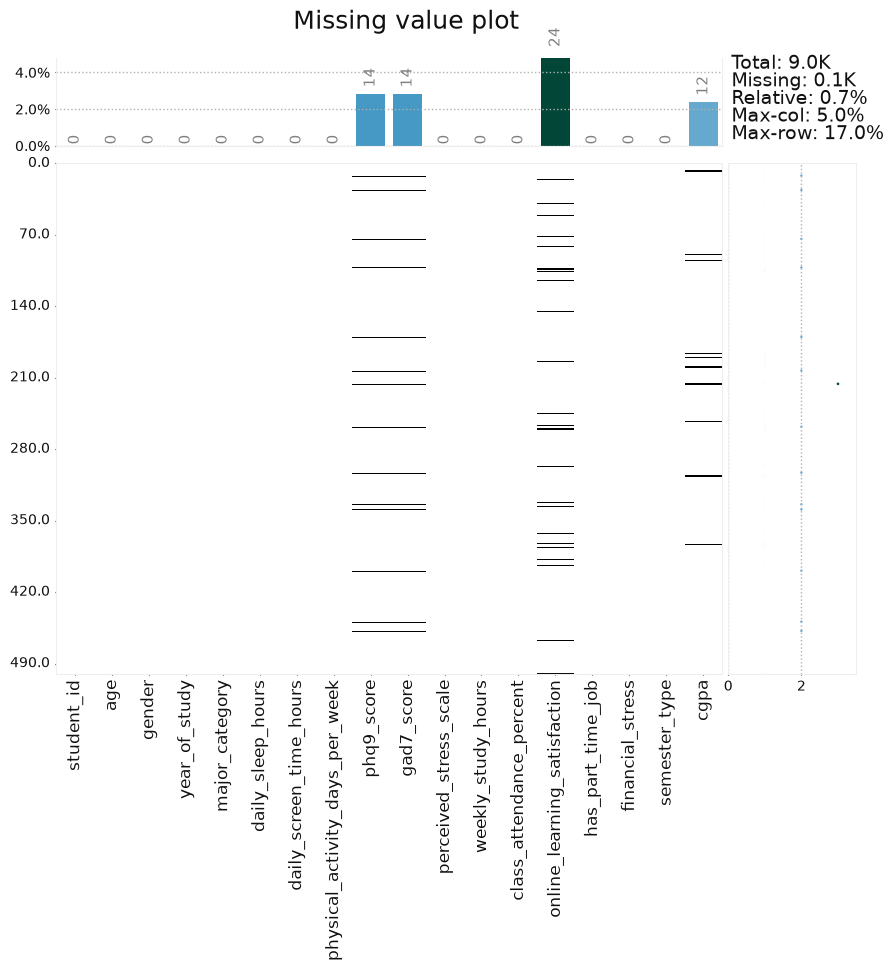

In [87]:
klib.missingval_plot(df,figsize=(10,8)) #tushirib qoldirilgan qiymatlar

In [88]:
klib.corr_interactive_plot(df) #input qiymatlar muhimliligi

In [89]:
klib.data_cleaning(df,drop_duplicates=True)

Shape of cleaned data: (500, 18) - Remaining NAs: 64


Dropped rows: 0
     of which 0 duplicates. (Rows (first 150 shown): [])

Dropped columns: 0
     of which 0 single valued.     Columns: []
Dropped missing values: 0
Reduced memory by at least: 0.05 MB (-71.43%)



,student_id,age,gender,year_of_study,major_category,daily_sleep_hours,daily_screen_time_hours,physical_activity_days_per_week,phq9_score,gad7_score,perceived_stress_scale,weekly_study_hours,class_attendance_percent,online_learning_satisfaction,has_part_time_job,financial_stress,semester_type,cgpa
0,STU1001,22,Female,3,Business,6.1,4.1,1,17.0,16.0,26,6.300000,63.900002,5.0,No,1,Spring,2.46
1,STU1002,19,M,2,Business,7.0,2.3,3,9.0,7.0,19,20.700001,78.500000,3.0,No,4,Fall,2.98
2,STU1003,23,Prefer not to say,3,STEM,5.0,9.2,1,1.0,2.0,10,17.100000,92.500000,5.0,No,3,Spring,3.27
3,STU1004,23,Male,2,Humanities,3.8,2.0,6,4.0,6.0,9,25.200001,86.500000,3.0,Yes,2,Spring,3.09
4,STU1005,17,Female,5,Arts,5.8,4.1,0,10.0,6.0,15,4.600000,83.900002,5.0,Yes,3,Spring,2.28
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
495,STU1496,23,Female,5,Law,5.9,6.8,2,4.0,4.0,10,5.900000,92.000000,2.0,No,5,Spring,2.93
496,STU1497,18,Female,3,STEM,5.0,1.6,3,5.0,5.0,9,18.299999,72.300003,5.0,No,5,Fall,2.46
497,STU1498,21,Female,3,STEM,5.9,9.8,0,4.0,1.0,6,30.900000,57.099998,4.0,No,3,Fall,3.14
498,STU1499,17,Male,4,STEM,5.5,6.8,2,3.0,6.0,13,19.500000,54.099998,4.0,No,5,Summer,2.75


In [90]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 18 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   student_id                       500 non-null    str    
 1   age                              500 non-null    int64  
 2   gender                           500 non-null    str    
 3   year_of_study                    500 non-null    int64  
 4   major_category                   500 non-null    str    
 5   daily_sleep_hours                500 non-null    float64
 6   daily_screen_time_hours          500 non-null    float64
 7   physical_activity_days_per_week  500 non-null    int64  
 8   phq9_score                       486 non-null    float64
 9   gad7_score                       486 non-null    float64
 10  perceived_stress_scale           500 non-null    int64  
 11  weekly_study_hours               500 non-null    float64
 12  class_attendance_percent         

# Datacleaner

In [91]:
pip install datacleaner


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [92]:
from datacleaner import autoclean

In [96]:
df=autoclean(df) #Autoclean ishlamayapdi menda

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/datacleaner/datacleaner.py:83: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  input_dataframe[column].fillna(input_dataframe[column].mode()[0], inplace=True)
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/datacleaner/datacl

In [95]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 18 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   student_id                       500 non-null    str    
 1   age                              500 non-null    int64  
 2   gender                           500 non-null    str    
 3   year_of_study                    500 non-null    int64  
 4   major_category                   500 non-null    str    
 5   daily_sleep_hours                500 non-null    float64
 6   daily_screen_time_hours          500 non-null    float64
 7   physical_activity_days_per_week  500 non-null    int64  
 8   phq9_score                       486 non-null    float64
 9   gad7_score                       486 non-null    float64
 10  perceived_stress_scale           500 non-null    int64  
 11  weekly_study_hours               500 non-null    float64
 12  class_attendance_percent         

In [108]:
def toldir(df):
    for col in df.columns:
        if df[col].isnull().any():
            if df[col].dtype=='str':
                df.fillna({col:df[col].mode()[0]},inplace=True)
            else:
                df.fillna({col:df[col].mean()},inplace=True)
    return df  

In [109]:
df=toldir(df)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 21 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   student_id                       500 non-null    int64  
 1   age                              500 non-null    int64  
 2   gender                           500 non-null    int64  
 3   year_of_study                    500 non-null    int64  
 4   major_category                   500 non-null    int64  
 5   daily_sleep_hours                500 non-null    float64
 6   daily_screen_time_hours          500 non-null    float64
 7   physical_activity_days_per_week  500 non-null    int64  
 8   phq9_score                       500 non-null    float64
 9   gad7_score                       500 non-null    float64
 10  perceived_stress_scale           500 non-null    int64  
 11  weekly_study_hours               500 non-null    float64
 12  class_attendance_percent         

In [110]:
from sklearn.preprocessing import LabelEncoder
encoder=LabelEncoder()
def encodla(df):
    for col in df.columns:
        if df[col].dtype=='str':
            if df[col].nunique()<=3:
                dummies=pd.get_dummies(df[col],prefix=col,dtype=int)
                df=pd.concat([df.drop(columns=col),dummies],axis=1)
            else:
                df[col]=encoder.fit_transform(df[col])
    return df    

In [111]:
df=encodla(df)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 21 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   student_id                       500 non-null    int64  
 1   age                              500 non-null    int64  
 2   gender                           500 non-null    int64  
 3   year_of_study                    500 non-null    int64  
 4   major_category                   500 non-null    int64  
 5   daily_sleep_hours                500 non-null    float64
 6   daily_screen_time_hours          500 non-null    float64
 7   physical_activity_days_per_week  500 non-null    int64  
 8   phq9_score                       500 non-null    float64
 9   gad7_score                       500 non-null    float64
 10  perceived_stress_scale           500 non-null    int64  
 11  weekly_study_hours               500 non-null    float64
 12  class_attendance_percent         

# Random Forest

In [112]:
# model selection
from sklearn.ensemble import RandomForestRegressor

In [113]:
rf=RandomForestRegressor()

In [114]:
# training
x=df.drop('cgpa',axis=1)
y=df['cgpa']

In [115]:
from sklearn.model_selection import train_test_split

In [116]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [117]:
x_train.shape

(400, 20)

In [118]:
y_train.shape

(400,)

In [119]:
rf.fit(x_train,y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [120]:
#prediction
y_pred=rf.predict(x_test)

In [121]:
y_pred[0]

np.float64(3.3814284836065567)

In [122]:
#evaluation
from sklearn.metrics import mean_absolute_error,root_mean_squared_error,mean_squared_error,r2_score

In [123]:
mae=mean_absolute_error(y_test,y_pred)
mse=mean_squared_error(y_test,y_pred)
r2=r2_score(y_test,y_pred)

In [124]:
print('mae=',mae)
print('mse=',mse)
print('r2=',r2)

mae= 0.2179951721311476
mse= 0.07160794804361563
r2= 0.3030636195926817
